In [12]:
import sys; sys.path.insert(0, "../src")
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from sfftradar.radial import load_seq, SEQS
from sfftradar.rd import row_inputs, doppler_power
from sfftradar.sparsity import dense_peaks
from sfftradar.sfft import flat_window, sparse_ops, dense_ops
from sfftradar.evaluate import row_recall

N = 256
WS = {B: flat_window(N, B)[0] for B in (16, 32, 64)}
STEP = 25

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
res = {}
rng = np.random.default_rng(0)
for tag in SEQS:
    seq = load_seq(tag)
    for B, w in WS.items():
        hit = tot = 0; cost = 0.0; nrows = 0; busy = 0
        for n in seq.frames[::STEP]:
            din = row_inputs(seq, n)
            P = doppler_power(din)
            med = np.median(P, axis=1)
            for r in range(512):
                h, t, rounds = row_recall(din[r], P[r], med[r] * 10, B, w, rng=rng)
                hit += h; tot += t; nrows += 1; busy += t > 0
                cost += sparse_ops(N, B, w, rounds)
        res[(tag, B)] = (hit / tot, cost / nrows / dense_ops(N), busy / nrows)
        print(f"{tag:12s} B={B:2d}  peaks kept {hit/tot:.2f}  cost vs dense {cost/nrows/dense_ops(N):.2f}  "
              f"skip-empty cost {busy/nrows:.2f}")

np.save("../results/phase3_real.npy", res)

city         B=16  peaks kept 0.03  cost vs dense 0.51  skip-empty cost 0.57
city         B=32  peaks kept 0.24  cost vs dense 1.29  skip-empty cost 0.57
city         B=64  peaks kept 0.61  cost vs dense 2.99  skip-empty cost 0.57
countryside  B=16  peaks kept 0.04  cost vs dense 0.46  skip-empty cost 0.40
countryside  B=32  peaks kept 0.27  cost vs dense 0.98  skip-empty cost 0.40
countryside  B=64  peaks kept 0.60  cost vs dense 2.12  skip-empty cost 0.40
highway      B=16  peaks kept 0.07  cost vs dense 0.46  skip-empty cost 0.28
highway      B=32  peaks kept 0.35  cost vs dense 0.85  skip-empty cost 0.28
highway      B=64  peaks kept 0.70  cost vs dense 1.70  skip-empty cost 0.28


In [14]:
res_c = {}
for tag in SEQS:
    seq = load_seq(tag)
    frames = seq.frames[::STEP]
    for c in (2.0, 4.0, 8.0):
        for B, w in WS.items():
            rng = np.random.default_rng(0)
            hit = tot = 0; cost = 0.0; nrows = 0
            for n in frames:
                din = row_inputs(seq, n)
                P = doppler_power(din)
                med = np.median(P, axis=1)
                for r in range(0, 512, 4):
                    h, t, rounds = row_recall(din[r], P[r], med[r] * 10, B, w, c=c, rng=rng)
                    hit += h; tot += t; nrows += 1
                    cost += sparse_ops(N, B, w, rounds)
            res_c[(tag, c, B)] = (hit / tot, cost / nrows / dense_ops(N))
            print(f"{tag:12s} c={c} B={B:2d}  kept {hit/tot:.2f}  cost {cost/nrows/dense_ops(N):.2f}")

np.save("../results/phase3_c_sweep.npy", res_c)

city         c=2.0 B=16  kept 0.30  cost 2.04
city         c=2.0 B=32  kept 0.70  cost 4.16
city         c=2.0 B=64  kept 0.92  cost 8.12
city         c=4.0 B=16  kept 0.03  cost 0.50
city         c=4.0 B=32  kept 0.24  cost 1.26
city         c=4.0 B=64  kept 0.62  cost 3.00
city         c=8.0 B=16  kept 0.00  cost 0.38
city         c=8.0 B=32  kept 0.06  cost 0.67
city         c=8.0 B=64  kept 0.28  cost 1.60
countryside  c=2.0 B=16  kept 0.31  cost 1.83
countryside  c=2.0 B=32  kept 0.70  cost 3.87
countryside  c=2.0 B=64  kept 0.93  cost 7.77
countryside  c=4.0 B=16  kept 0.04  cost 0.46
countryside  c=4.0 B=32  kept 0.28  cost 1.04
countryside  c=4.0 B=64  kept 0.59  cost 2.14
countryside  c=8.0 B=16  kept 0.01  cost 0.38
countryside  c=8.0 B=32  kept 0.09  cost 0.62
countryside  c=8.0 B=64  kept 0.27  cost 1.19
highway      c=2.0 B=16  kept 0.36  cost 1.45
highway      c=2.0 B=32  kept 0.74  cost 3.23
highway      c=2.0 B=64  kept 0.95  cost 6.74
highway      c=4.0 B=16  kept 0.06

In [15]:
res_e = {}
for tag in SEQS:
    seq = load_seq(tag)
    hit = {}; kept = {}; tot = 0; nrows = 0
    alphas = (1.0, 1.2, 1.5, 2.0, 3.0)
    for n in seq.frames[::STEP]:
        din = row_inputs(seq, n)
        P = np.sum(np.abs(np.fft.fft(din, axis=1)) ** 2, axis=2)
        med = np.median(P, axis=1)
        E = np.sum(np.abs(din) ** 2, axis=(1, 2))          # energy of each row (cheap, no FFT)
        for r in range(512):
            pk = dense_peaks(P[r], med[r] * 10)
            tot += len(pk); nrows += 1
            for a in alphas:
                if E[r] > a * np.median(E):                  # row "not empty": run the dense FFT
                    hit[a] = hit.get(a, 0) + len(pk)
                    kept[a] = kept.get(a, 0) + 1
    for a in alphas:
        k_share = hit.get(a, 0) / tot
        cost = 0.125 + kept.get(a, 0) / nrows               # energy test + dense FFT on kept rows
        res_e[(tag, a)] = (k_share, cost)
        print(f"{tag:12s} a={a}  kept {k_share:.2f}  cost {cost:.2f}")

np.save("../results/phase3_energy_skip.npy", res_e)

city         a=1.0  kept 0.82  cost 0.62
city         a=1.2  kept 0.79  cost 0.54
city         a=1.5  kept 0.74  cost 0.47
city         a=2.0  kept 0.67  cost 0.41
city         a=3.0  kept 0.56  cost 0.34
countryside  a=1.0  kept 0.79  cost 0.62
countryside  a=1.2  kept 0.78  cost 0.50
countryside  a=1.5  kept 0.74  cost 0.42
countryside  a=2.0  kept 0.65  cost 0.35
countryside  a=3.0  kept 0.52  cost 0.27
highway      a=1.0  kept 0.70  cost 0.62
highway      a=1.2  kept 0.69  cost 0.46
highway      a=1.5  kept 0.65  cost 0.35
highway      a=2.0  kept 0.55  cost 0.27
highway      a=3.0  kept 0.43  cost 0.21


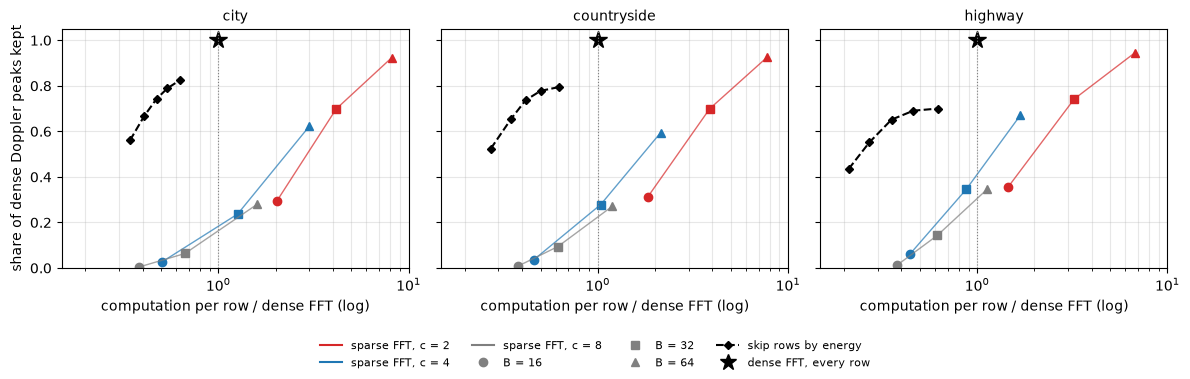

In [16]:
import matplotlib.pyplot as plt

res_c = np.load("../results/phase3_c_sweep.npy", allow_pickle=True).item()
res_e = np.load("../results/phase3_energy_skip.npy", allow_pickle=True).item()
marks = {16: "o", 32: "s", 64: "^"}
cols  = {2.0: "C3", 4.0: "C0", 8.0: "C7"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, tag in zip(axes, SEQS):
    for c, col in cols.items():                                  # sparse FFT, one line per threshold c
        xs = [res_c[(tag, c, B)][1] for B in (16, 32, 64)]
        ys = [res_c[(tag, c, B)][0] for B in (16, 32, 64)]
        ax.plot(xs, ys, "-", color=col, lw=1, alpha=0.7)
        for B, x, y in zip((16, 32, 64), xs, ys):
            ax.plot(x, y, marks[B], color=col, ms=6)
    ea = [res_e[(tag, a)] for a in (3.0, 2.0, 1.5, 1.2, 1.0)]     # energy skip
    ax.plot([e[1] for e in ea], [e[0] for e in ea], "k--", lw=1.5, marker="D", ms=4)
    ax.plot(1.0, 1.0, "k*", ms=13)                                # dense FFT, every row
    ax.axvline(1.0, color="gray", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_xlim(0.15, 10); ax.set_ylim(0, 1.05)
    ax.set_title(tag, fontsize=10); ax.grid(alpha=0.3, which="both")
    ax.set_xlabel("computation per row / dense FFT (log)")
axes[0].set_ylabel("share of dense Doppler peaks kept")

from matplotlib.lines import Line2D
h = [Line2D([], [], color=cols[c], lw=1.5, label=f"sparse FFT, c = {c:g}") for c in cols]
h += [Line2D([], [], color="gray", marker=marks[B], ls="", label=f"B = {B}") for B in marks]
h += [Line2D([], [], color="k", ls="--", marker="D", ms=4, label="skip rows by energy"),
      Line2D([], [], color="k", marker="*", ls="", ms=12, label="dense FFT, every row")]
fig.legend(handles=h, loc="lower center", ncol=4, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig("../figures/fig3_recall_vs_cost.png", dpi=150)
plt.show()